
# OASIS INFOBYTE Data Science Internship
# Task 4: Email Spam Detection with Machine Learning

## 1. Introduction

Spam messages are unwanted messages that may contain advertisements, fraudulent offers, or suspicious links. Detecting spam automatically helps users identify unwanted messages and reduce the risk of phishing and online scams.

In this project, we will use Natural Language Processing (NLP) and machine learning to classify text messages into two categories: spam and ham (legitimate messages).

## 2. Problem Statement

Manually identifying spam messages can be time-consuming and unreliable. The objective of this project is to develop a machine learning classifier that learns patterns from labelled messages and predicts whether a new message is spam or legitimate.

## 3. Objectives

- Load and inspect a labelled spam-message dataset.
- Analyze the distribution of spam and legitimate messages.
- Clean and preprocess text data.
- Convert text into numerical features using TF-IDF.
- Train and compare multiple classification models.
- Evaluate models using accuracy, precision, recall, F1-score, and confusion matrices.
- Analyze misclassified messages.
- Explain the importance of recall in spam detection.
- Select the best-performing model using appropriate evaluation metrics.

## 4. Dataset Description

This project will use the SMS Spam Collection dataset, which contains text messages labelled as spam or ham. The dataset typically contains a message label and the corresponding message text.

The exact number of records and column structure will be confirmed during data loading.

## 5. Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Regular Expressions (re)
- TF-IDF Vectorization

## 6. Project Workflow

1. Load and inspect the dataset.
2. Clean and preprocess text messages.
3. Explore spam and ham distributions.
4. Transform text using TF-IDF.
5. Split data into training and testing sets.
6. Train and compare classification models.
7. Evaluate model performance and inspect errors.
8. Present findings, limitations, and conclusion.

## 7. Expected Outcome

The expected outcome is a text-classification model that identifies potential spam messages and distinguishes them from legitimate messages. The project will also compare model performance and examine the trade-off between detecting spam and incorrectly flagging legitimate messages.


In [1]:

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:

from tkinter import Tk, filedialog

root = Tk()
root.withdraw()
root.attributes("-topmost", True)

file_path = filedialog.askopenfilename(
    title="Select SMS Spam Collection Dataset",
    filetypes=[
        ("Text or CSV files", "*.txt *.csv"),
        ("All files", "*.*")
    ]
)

root.destroy()

if not file_path:
    raise ValueError("No file selected. Run this cell again.")

if file_path.lower().endswith(".csv"):
    df = pd.read_csv(file_path, encoding="latin-1")
    print("CSV dataset loaded.")
else:
    df = pd.read_csv(
        file_path,
        sep="\t",
        header=None,
        names=["label", "message"],
        encoding="utf-8"
    )
    print("Tab-separated dataset loaded.")

print("Dataset shape:", df.shape)
display(df.head())


CSV dataset loaded.
Dataset shape: (5572, 5)


,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [7]:

# Step 4: Inspect and clean dataset columns

print("Original shape:", df.shape)
print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Remove completely empty columns
df = df.dropna(axis=1, how="all")

# Rename columns
df = df.rename(columns={
    "v1": "label",
    "v2": "message"
})

# Keep only the required columns
df = df[["label", "message"]]

print("\nShape after cleaning:", df.shape)
print("\nColumn names:", df.columns.tolist())
display(df.head())


Original shape: (5572, 5)

Missing values before cleaning:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

Shape after cleaning: (5572, 2)

Column names: ['label', 'message']


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [8]:

# Step 5: Check data quality

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nLabel counts:")
print(df["label"].value_counts())

print("\nUnique labels:", df["label"].unique())
print("Duplicate rows:", df.duplicated().sum())


Dataset shape: (5572, 2)

Missing values:
label      0
message    0
dtype: int64

Label counts:
label
ham     4825
spam     747
Name: count, dtype: int64

Unique labels: <ArrowStringArray>
['ham', 'spam']
Length: 2, dtype: str
Duplicate rows: 403


In [9]:

# Step 6: Clean data

df["label"] = df["label"].astype(str).str.strip().str.lower()
df["message"] = df["message"].fillna("").astype(str).str.strip()

df = df.drop_duplicates().reset_index(drop=True)
df = df[df["label"].isin(["ham", "spam"])].copy()
df = df[df["message"] != ""].reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("Missing values:\n", df.isnull().sum())
print("Labels:\n", df["label"].value_counts())


Shape after cleaning: (5158, 2)
Missing values:
 label      0
message    0
dtype: int64
Labels:
 label
ham     4516
spam     642
Name: count, dtype: int64


Class counts:
 label
ham     4516
spam     642
Name: count, dtype: int64

Class percentages:
 label
ham     87.55
spam    12.45
Name: proportion, dtype: float64


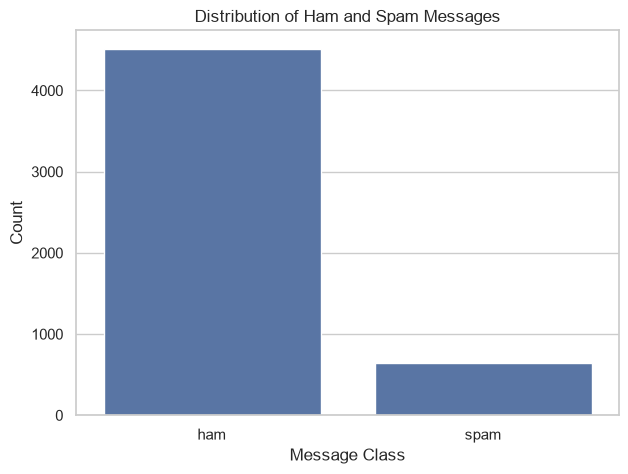

In [11]:

# Step 7: Class distribution

import matplotlib.pyplot as plt
import seaborn as sns

label_counts = df["label"].value_counts()
label_percentages = df["label"].value_counts(normalize=True).mul(100)

print("Class counts:\n", label_counts)
print("\nClass percentages:\n", label_percentages.round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="label")
plt.title("Distribution of Ham and Spam Messages")
plt.xlabel("Message Class")
plt.ylabel("Count")
plt.show()



### Class Distribution

The dataset contains normal messages (ham) and unwanted messages (spam). The class distribution helps identify whether the dataset is imbalanced. If spam messages are fewer, accuracy alone may not be sufficient to evaluate the model.


In [13]:

# Step 8: Clean message text

import re
import string

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_message"] = df["message"].apply(clean_text)

display(df[["message", "clean_message", "label"]].head(10))


,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...,ham
1,Ok lar... Joking wif u oni...,ok lar joking wif u oni,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in a wkly comp to win fa cup final ...,spam
3,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say,ham
4,"Nah I don't think he goes to usf, he lives aro...",nah i dont think he goes to usf he lives aroun...,ham
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling its been weeks now a...,spam
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...,ham
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...,ham
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...,spam
9,Had your mobile 11 months or more? U R entitle...,had your mobile months or more u r entitled to...,spam



### Text Preprocessing

Text is converted to lowercase, URLs and email addresses are removed, punctuation and digits are removed, and extra spaces are reduced. These steps make text more consistent for machine learning. Original messages are retained for later inspection.



### TF-IDF Vectorization

TF-IDF stands for Term Frequency–Inverse Document Frequency. It converts text into numerical features that machine learning models can understand. Words that are frequent in one message but less common across all messages can receive higher importance. TF-IDF is fitted only on the training data through a pipeline to prevent data leakage.


In [14]:

# Step 10: Train-test split

from sklearn.model_selection import train_test_split

X = df["clean_message"]
y = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining label distribution:")
print(y_train.value_counts())


Training samples: 4126
Testing samples: 1032

Training label distribution:
label
ham     3612
spam     514
Name: count, dtype: int64


In [15]:

# Step 11: Multinomial Naive Bayes model

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB

nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB())
])

nb_model.fit(X_train, y_train)
nb_predictions = nb_model.predict(X_test)

print("Naive Bayes training completed.")
print("Predictions:", nb_predictions[:10])


Naive Bayes training completed.
Predictions: ['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [16]:

# Step 12: Evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

nb_accuracy = accuracy_score(y_test, nb_predictions)
nb_precision = precision_score(
    y_test, nb_predictions, pos_label="spam", zero_division=0
)
nb_recall = recall_score(
    y_test, nb_predictions, pos_label="spam", zero_division=0
)
nb_f1 = f1_score(
    y_test, nb_predictions, pos_label="spam", zero_division=0
)

print("Naive Bayes Results")
print(f"Accuracy : {nb_accuracy:.4f}")
print(f"Spam Precision: {nb_precision:.4f}")
print(f"Spam Recall   : {nb_recall:.4f}")
print(f"Spam F1-score : {nb_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, nb_predictions, zero_division=0))


Naive Bayes Results
Accuracy : 0.9690
Spam Precision: 1.0000
Spam Recall   : 0.7500
Spam F1-score : 0.8571

Classification Report:
              precision    recall  f1-score   support

         ham       0.97      1.00      0.98       904
        spam       1.00      0.75      0.86       128

    accuracy                           0.97      1032
   macro avg       0.98      0.88      0.92      1032
weighted avg       0.97      0.97      0.97      1032



In [17]:

# Step 13: Logistic Regression model

from sklearn.linear_model import LogisticRegression

lr_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)

print("Logistic Regression training completed.")


Logistic Regression training completed.


In [18]:

# Step 14: Compare model performance

lr_accuracy = accuracy_score(y_test, lr_predictions)
lr_precision = precision_score(
    y_test, lr_predictions, pos_label="spam", zero_division=0
)
lr_recall = recall_score(
    y_test, lr_predictions, pos_label="spam", zero_division=0
)
lr_f1 = f1_score(
    y_test, lr_predictions, pos_label="spam", zero_division=0
)

results = pd.DataFrame({
    "Model": ["Multinomial Naive Bayes", "Logistic Regression"],
    "Accuracy": [nb_accuracy, lr_accuracy],
    "Spam Precision": [nb_precision, lr_precision],
    "Spam Recall": [nb_recall, lr_recall],
    "Spam F1-score": [nb_f1, lr_f1]
})

display(results.round(4))


,Model,Accuracy,Spam Precision,Spam Recall,Spam F1-score
0,Multinomial Naive Bayes,0.9690,1.0000,0.7500,0.8571
1,Logistic Regression,0.9806,0.9286,0.9141,0.9213


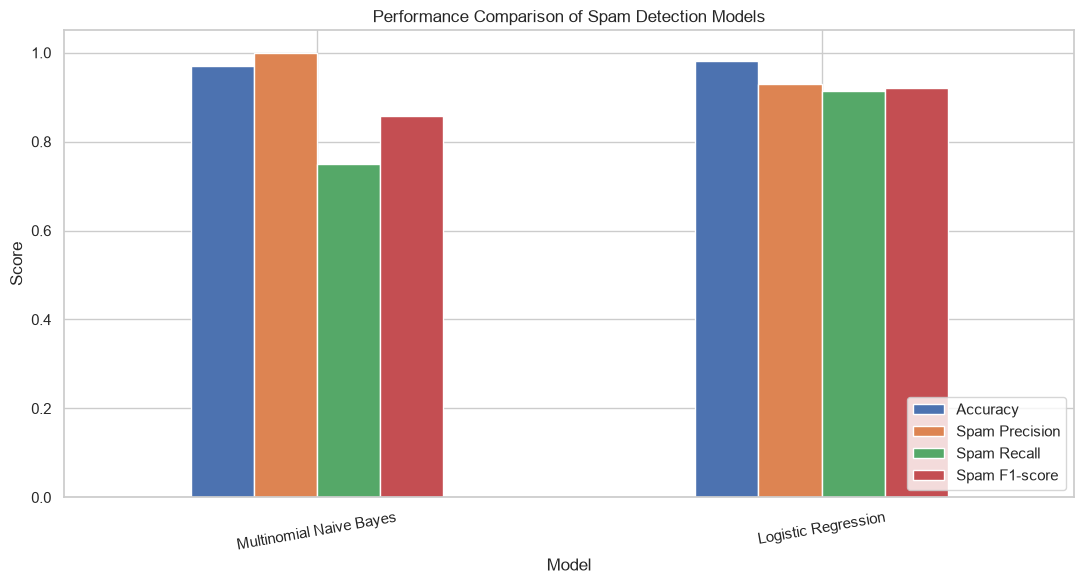

In [19]:

# Step 15: Compare evaluation metrics

results_plot = results.set_index("Model")[
    ["Accuracy", "Spam Precision", "Spam Recall", "Spam F1-score"]
]

results_plot.plot(kind="bar", figsize=(11, 6), ylim=(0, 1.05))
plt.title("Performance Comparison of Spam Detection Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=10)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


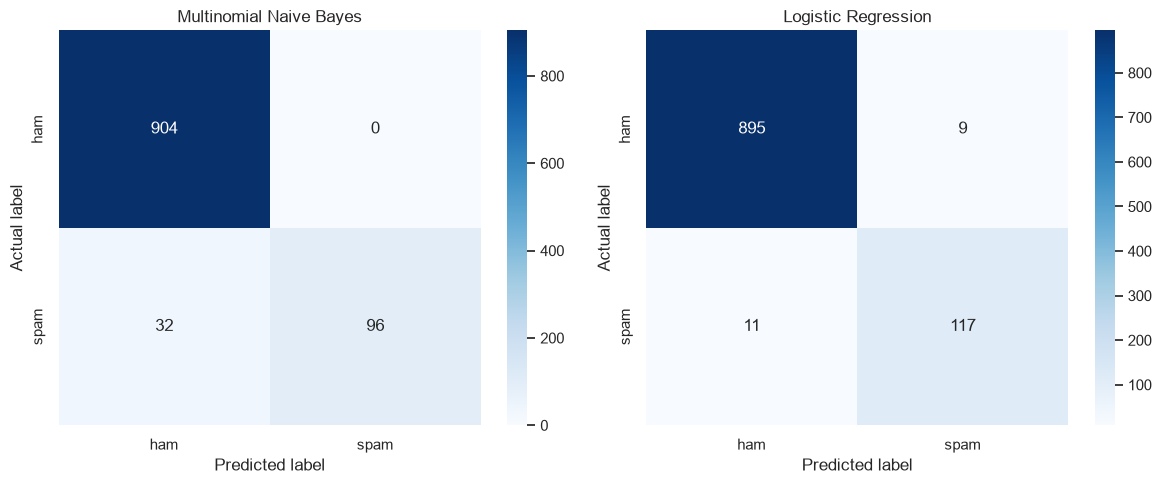

In [20]:

# Step 16: Confusion matrices

from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, model_name, predictions in [
    (axes[0], "Multinomial Naive Bayes", nb_predictions),
    (axes[1], "Logistic Regression", lr_predictions)
]:
    cm = confusion_matrix(
        y_test, predictions, labels=["ham", "spam"]
    )
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["ham", "spam"],
        yticklabels=["ham", "spam"],
        ax=ax
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")

plt.tight_layout()
plt.show()



### Confusion Matrix Interpretation

- True Positive: A spam message correctly predicted as spam.
- True Negative: A ham message correctly predicted as ham.
- False Positive: A normal message incorrectly predicted as spam.
- False Negative: A spam message incorrectly predicted as normal.

The confusion matrix shows which types of classification errors each model makes.



### Importance of Recall in Spam Detection

Spam recall measures the proportion of actual spam messages correctly identified by the model. Low recall means more spam messages reach the user's inbox. However, precision also matters because low precision can cause important normal messages to be marked as spam. A good model should balance recall and precision.


In [21]:

# Step 18: Error analysis for the best-performing model

best_model_name = (
    "Multinomial Naive Bayes"
    if nb_f1 >= lr_f1
    else "Logistic Regression"
)

best_model = nb_model if nb_f1 >= lr_f1 else lr_model
best_predictions = nb_predictions if nb_f1 >= lr_f1 else lr_predictions

error_analysis = pd.DataFrame({
    "Actual": y_test.reset_index(drop=True),
    "Predicted": pd.Series(best_predictions),
    "Message": df.loc[X_test.index, "message"].reset_index(drop=True)
})

errors = error_analysis[
    error_analysis["Actual"] != error_analysis["Predicted"]
]

print("Selected model:", best_model_name)
print("Total misclassified messages:", len(errors))
display(errors.head(15))


Selected model: Logistic Regression
Total misclassified messages: 20


,Actual,Predicted,Message
18,ham,spam,Ok... Ur typical reply...
77,spam,ham,Cashbin.co.uk (Get lots of cash this weekend!)...
146,ham,spam,"Call me da, i am waiting for your call."
148,ham,spam,"Madam,regret disturbance.might receive a refer..."
164,ham,spam,Plz note: if anyone calling from a mobile Co. ...
205,spam,ham,Sorry I missed your call let's talk when you h...
241,ham,spam,Host-based IDPS for linux systems.
323,spam,ham,Sorry! U can not unsubscribe yet. THE MOB offe...
354,spam,ham,Hi I'm sue. I am 20 years old and work as a la...
389,spam,ham,Babe: U want me dont u baby! Im nasty and have...


In [22]:


# Step 19: Predict new SMS messages

test_messages = [
    "Congratulations! You have won a free prize. Claim now!",
    "Hey, are we meeting for lunch today?",
    "URGENT! You have won cash. Call now to claim your reward.",
    "I will reach home in ten minutes."
]

cleaned_messages = [clean_text(message) for message in test_messages]
predictions = best_model.predict(cleaned_messages)

for message, prediction in zip(test_messages, predictions):
    print(f"Message: {message}")
    print(f"Prediction: {prediction.upper()}")
    print("-" * 60)


Message: Congratulations! You have won a free prize. Claim now!
Prediction: SPAM
------------------------------------------------------------
Message: Hey, are we meeting for lunch today?
Prediction: HAM
------------------------------------------------------------
Message: URGENT! You have won cash. Call now to claim your reward.
Prediction: SPAM
------------------------------------------------------------
Message: I will reach home in ten minutes.
Prediction: HAM
------------------------------------------------------------


In [23]:

# Step 20: Final model selection

best_results = results.loc[results["Spam F1-score"].idxmax()]

print("Best model based on spam F1-score:")
print(best_results)

print("\nSelected model:", best_model_name)


Best model based on spam F1-score:
Model             Logistic Regression
Accuracy                      0.98062
Spam Precision               0.928571
Spam Recall                  0.914062
Spam F1-score                 0.92126
Name: 1, dtype: object

Selected model: Logistic Regression


In [24]:

# Step 21: Save the trained model

import joblib

model_filename = "sms_spam_detection_model.pkl"
joblib.dump(best_model, model_filename)

print("Model saved as:", model_filename)


Model saved as: sms_spam_detection_model.pkl



# Conclusion

The SMS Spam Detection project uses Natural Language Processing (NLP) and machine learning to classify SMS messages as spam or ham.

The dataset was inspected and cleaned, text preprocessing was performed, and TF-IDF was used to convert text into numerical features. Multinomial Naive Bayes and Logistic Regression were trained and compared using accuracy, precision, recall, F1-score, and confusion matrices.

The final model was selected based on its spam F1-score. Recall and precision were also considered because missed spam messages and incorrectly blocked normal messages both affect users.

This project demonstrates how NLP and machine learning can help identify unwanted SMS messages.


In [25]:

# Step 23: Final verification

print("========== FINAL PROJECT CHECK ==========")
print("Dataset shape:", df.shape)
print("Dataset columns:", df.columns.tolist())
print("Missing values:", df[["label", "message"]].isnull().sum().sum())
print("Duplicate rows remaining:", df.duplicated().sum())
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Models trained: Multinomial Naive Bayes, Logistic Regression")
print("Best model:", best_model_name)
print(f"Best model spam F1-score: {best_results['Spam F1-score']:.4f}")
print("Saved model exists:", __import__("os").path.exists(model_filename))
print("=========================================")


========== FINAL PROJECT CHECK ==========
Dataset shape: (5158, 3)
Dataset columns: ['label', 'message', 'clean_message']
Missing values: 0
Duplicate rows remaining: 0
Training samples: 4126
Testing samples: 1032
Models trained: Multinomial Naive Bayes, Logistic Regression
Best model: Logistic Regression
Best model spam F1-score: 0.9213
Saved model exists: True
